# 01 — Problem, data, and findings

This notebook establishes the problem before we choose features or models: **what data and signals were we given, and why can they not be copied directly into H/A/D labels?**

The notebook is descriptive.

- Each section explains one signal.
- The next code cell checks it against our local files.
- No model is trained here.
- Public labels are used only for a small descriptive sanity check; they are not used for tuning.

## The problem in one sentence

For every tactical frame, classify the match state as Home possession (`H`), Away possession (`A`), dead ball (`D`), or outside the scored intervals (`X`). The difficult part is not calculating a distance; it is distinguishing a genuine controlled reception from a one-frame touch, a contested ball, or a ball in flight.

George's optional alternate-camera table adds ball availability, source, gap, and uncertainty observations. We inspect those as measurement quality; they are not possession labels.

## Notebook map

```text
1. ATD tracking       → players and ball
2. Homography         → pitch coordinates ↔ image pixels
3. Smart Tagging      → automatic football-phase context
4. Merged frame table → small model-ready evidence table
```

The public sanity window is `11,185–18,684`.

Later examples use middle frames from the graded halves.
Their labels are hidden.

In [1]:
# Purpose: load the local files and define the paths used by every evidence section.
import os
from pathlib import Path
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
# Update MTAH_DATA_DIR here when the gated data lives elsewhere.
DATA_CANDIDATES = []
if os.environ.get('MTAH_DATA_DIR'):
    DATA_CANDIDATES.append(Path(os.environ['MTAH_DATA_DIR']))
DATA_CANDIDATES.extend([ROOT / 'data', ROOT.parent / 'data'])
DATA = next((candidate.resolve() for candidate in DATA_CANDIDATES if (candidate / 'tactical').exists()), None)
if DATA is None:
    raise FileNotFoundError('Set MTAH_DATA_DIR in notebook 00 to the folder containing tactical/')
os.environ['MTAH_DATA_DIR'] = str(DATA)
TACTICAL = DATA / 'tactical'
sys.path.insert(0, str(ROOT))

print('Project root:', ROOT)
print('Tactical files:')
for path in sorted(TACTICAL.glob('*')):
    print(f'  {path.name}: {path.stat().st_size / 1024**2:.1f} MB')
print('Submission frames: 0..199318 (199,319 rows)')

Project root: /Users/luke/Desktop/barca-hack-repo-staging
Tactical files:
  .gitkeep: 0.0 MB
  BAR-ATH_tactical.mp4: 4980.4 MB
  BAR-ATH_tactical_atd.txt: 186.6 MB
  BAR-ATH_tactical_atd.xml: 0.1 MB
  BAR-ATH_tactical_homography.csv: 22.1 MB
  BAR-ATH_tactical_smart_tagging.xml: 0.2 MB
Submission frames: 0..199318 (199,319 rows)


## 1. ATD — Automatic Tracking Data

ATD means **Automatic Tracking Data**.

It estimates: 
- the ball position;
- player-track positions;
- supplied movement values.

The coordinates are on the pitch, not camera pixels.

### ATD column glossary

| Column pattern | Data given | Glossary / meaning | How we may use it |
|---|---|---|---|
| `period_id` | period number | Which recording period the row belongs to | Separate match periods |
| `timestamp` | time value | Time associated with the frame | Order and time-based features |
| `frame_id` | integer `1..199319` | ATD's 1-based frame counter | Convert to submission frame with `frame_id - 1` |
| `ball_state` | provider field | Ball-state field from the tracking export | Inspect, but check missingness first |
| `ball_owning_team_id` | provider team ID | Provider's ball-owner field | Inspect, but it is not our final `H/A/D` label |
| `ball_x`, `ball_y` | number or missing | Ball position in normalised pitch coordinates, not image pixels | Ball location and visibility |
| `ball_z` | number or missing | Ball height coordinate, if supplied | Detect airborne balls if populated |
| `ball_speed` | number or missing | Ball speed field, if supplied | Ball movement features |
| `k_x` | number or missing | x-position of temporary track slot `k` in normalised pitch coordinates, not image pixels | Player location |
| `k_y` | number or missing | y-position of temporary track slot `k` in normalised pitch coordinates, not image pixels | Player location |
| `k_d` | partially populated here | Parsed third slot field; its semantics are not relied on by the baseline | Treat as optional until separately validated |
| `k_s` | number or missing | Supplied speed for slot `k` | Movement features |

Example: `44_x`, `44_y`, `44_d`, `44_s` describe temporary **track slot 44**.

They do not mean player number 44.

- x/y are normalised pitch coordinates, approximately `0..1`;
- x/y are not image pixels;
- `_d` is only partially populated in this export and is not relied on by the baseline;
- the XML describes speed as km/h.

In [2]:
# Purpose: load ATD and show its shape, frame convention, sample columns, and missingness.
from kloppy import metrica

atd_dataset = metrica.load_tracking_epts(
    meta_data=TACTICAL / 'BAR-ATH_tactical_atd.xml',
    raw_data=TACTICAL / 'BAR-ATH_tactical_atd.txt',
)
atd = atd_dataset.to_df()

print('Shape:', atd.shape)
print('Frame IDs:', atd.frame_id.min(), 'to', atd.frame_id.max())
print('Submission frames:', atd.frame_id.min() - 1, 'to', atd.frame_id.max() - 1)

core_columns = ['period_id', 'timestamp', 'frame_id', 'ball_state', 'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed']
track_columns = ['1_x', '1_y', '1_d', '1_s', '44_x', '44_y', '44_d', '44_s', '46_x', '46_y', '46_d', '46_s']
available_columns = [column for column in core_columns + track_columns if column in atd.columns]
print('\nReadable sample:')
print(atd[available_columns].head(3).to_string(index=False))

print('\nMissingness of important fields:')
missingness = atd[available_columns].isna().mean().mul(100).round(1)
print(missingness.to_string())

Shape: (199319, 193)
Frame IDs: 1 to 199319
Submission frames: 0 to 199318

Readable sample:
 period_id              timestamp  frame_id ball_state ball_owning_team_id  ball_x  ball_y ball_z ball_speed     1_x     1_y  1_d      1_s  44_x  44_y 44_d  44_s    46_x    46_y 46_d  46_s
         1 0 days 00:00:00.040000         1       None                None     NaN     NaN   None       None 0.33411 0.90565 None 0.886863   NaN   NaN None   NaN 0.06057 0.39965 None   NaN
         1 0 days 00:00:00.080000         2       None                None     NaN     NaN   None       None 0.33404 0.90487 None 0.886863   NaN   NaN None   NaN 0.06057 0.39965 None   NaN
         1 0 days 00:00:00.120000         3       None                None     NaN     NaN   None       None 0.33396 0.90413 None 0.886863   NaN   NaN None   NaN 0.06057 0.39965 None   NaN

Missingness of important fields:
period_id                0.0
timestamp                0.0
frame_id                 0.0
ball_state             100.0
b

## 2. Homography — the camera-to-pitch map

A camera views the pitch at an angle.

The flat pitch is therefore distorted in the image.

A Homography is the mathematical mapping from pitch coordinates to that camera's pixels.

There are two files:

- **Tactical** → aligned to the submission timeline; used below.
- **Broadcast** → paired with broadcast ATD/video; not synchronised.

Broadcast use requires a separate alignment step.

```text
ATD pitch position (x, y) → video pixel position (u, v)
```

### Homography column glossary

| Column | Data given | Glossary / meaning |
|---|---|---|
| `frame` | integer `0..199318` | 0-based tactical video frame |
| `h00..h22` | 9 numbers | The 3×3 transform matrix, stored row by row |
| `reprojection_error` | number | How far projected reference points miss their expected image locations; lower is generally better |
| `valid` | `0` or `1` | Whether the geometry estimate is marked usable |

Matrix layout:

    [h00 h01 h02]
    [h10 h11 h12]
    [h20 h21 h22]

Key distinction:

- ATD gives normalised pitch coordinates.
- Homography converts them to image pixels.
- Homography does not identify possession.
- It helps project tracking positions onto video.

### Do we need pixel positions?

Not for every model. ATD pitch coordinates are enough for:

- distances between players and the ball;
- team shape and spacing;
- nearest-player and pressure features.

Pixel positions help when we want to:

- draw ATD locations on the video;
- inspect whether a tracking point looks correct;
- combine tracking with image-based features, such as a crop or visual detector.

So Homography is an optional bridge from pitch-space data to camera-image data. It does not add a new player location; it expresses the same location in a different coordinate system.

In [3]:
# Purpose: load Homography and verify the matrix columns, frame range, validity, and error.
homography = pd.read_csv(TACTICAL / 'BAR-ATH_tactical_homography.csv')
matrix_columns = ['h00', 'h01', 'h02', 'h10', 'h11', 'h12', 'h20', 'h21', 'h22']

print('Shape:', homography.shape)
print('Frame IDs:', homography.frame.min(), 'to', homography.frame.max())
print('All nine matrix columns present:', set(matrix_columns).issubset(homography.columns))
print('Valid proportion:', round(homography.valid.mean(), 4))
print('Mean reprojection error:', round(homography.reprojection_error.mean(), 4))
print('\nReadable sample:')
print(homography[['frame', *matrix_columns, 'reprojection_error', 'valid']].head(3).to_string(index=False))

Shape: (199319, 12)
Frame IDs: 0 to 199318
All nine matrix columns present: True
Valid proportion: 1.0
Mean reprojection error: 0.4229

Readable sample:
 frame        h00         h01       h02      h10        h11        h12       h20       h21  h22  reprojection_error  valid
     0 1834.51428 -519.781433 45.983478 5.733814 162.882401 256.334229 -0.008851 -0.534427    1            0.589505      1
     1 1834.55481 -519.716187 45.878456 5.647519 162.892273 256.363373 -0.008816 -0.534435    1            0.574035      1
     2 1834.59546 -519.650940 45.773430 5.561231 162.902145 256.392517 -0.008781 -0.534442    1            0.558565      1


## 3. Smart Tagging — automatic football-phase context

Smart Tagging is automatic football-analysis context.

It marks intervals that look like phases or events,
such as restarts and set pieces.

### Smart Tagging column glossary

| Field | Data given | Glossary / meaning |
|---|---|---|
| `code` | text | Broad event/phase category, such as `SET PIECES` |
| `start_s` / `end_s` | seconds | Start and end time of the tagged interval |
| `start_frame` / `end_frame` | frame IDs | Start and end of the tagged interval on the tactical timeline |
| `tags` | dictionary | More detailed context, such as team, type, or half |

Use it to ask:

> What type of football phase may be happening?

It is not the official possession label.
Treat it as context and expect some errors.

In [4]:
# Purpose: load Smart Tagging and show event counts plus one parsed event.
from starter.load_smart_tagging import load as load_smart_tagging

events = load_smart_tagging()
print('Number of events:', len(events))
print('Event codes:')
print(pd.Series([event['code'] for event in events]).value_counts().to_string())
print('\nOne event example:')
print(events[0])

Number of events: 638
Event codes:
PLAYERS IN THE BOX              97
BALL IN FINAL THIRD             93
BALL IN THE BOX                 72
PROGRESSION                     66
DEFENDING IN MIDDLE THIRD       66
SET PIECES                      59
CREATING CHANCES                30
DEFENDING IN DEFENSIVE THIRD    30
LONG BALL                       29
ATTACKING TRANSITION            24
DEFENSIVE TRANSITION            24
BUILD UP                        22
DEFENDING IN ATTACKING THIRD    22
GOALS                            4

One event example:
{'code': 'SET PIECES', 'start_s': 443.88, 'end_s': 448.88, 'start_frame': 11097, 'end_frame': 11222, 'tags': {'Team': 'N/A', 'Type': 'Kick Off (Start)', 'Half': '1st Half'}}


## Finding: Smart Tagging is context, not frame-level ground truth

We use the public five-minute labels here only as a descriptive sanity check. The question is not whether Smart Tagging is useless; it is whether one tagged interval can be copied directly to every frame.

The next cell measures overlap for `SET PIECES` in the public window and shows one public-window trajectory plot. The plot is evidence for the problem: a tag spans a time interval, while the ball visibility, player geometry, and true `D`/H/A labels can change within that interval.

Operational conclusion → use Smart Tagging to open a scenario window; use ATD geometry and controlled-reception evidence to make the frame-level decision.

Public SET PIECES frames: 1190
Labels inside those frames: {'D': 667, 'H': 296, 'A': 227}
D precision inside SET PIECES: 0.561
Public D coverage by SET PIECES: 0.454


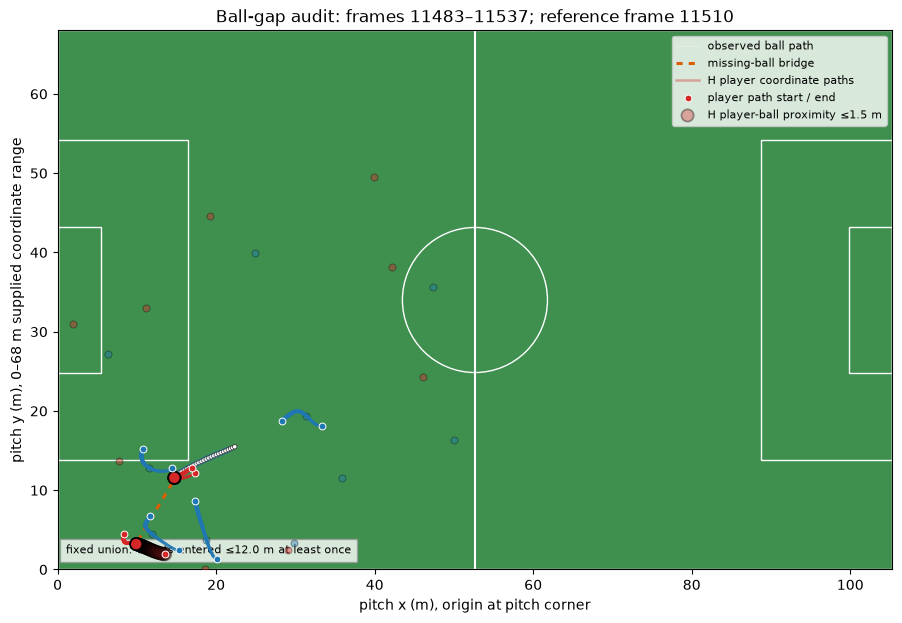

In [5]:
# Purpose: quantify Smart Tagging's public-window coverage and plot one public ball gap.
from possession.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession.calculations.plotting import plot_trajectory_window, select_representative_ball_gap
from games import asset_paths
from starter.load_smart_tagging import load as load_smart_tagging
import matplotlib.pyplot as plt

public_gt = pd.read_csv(ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv')
public_mask = public_gt['frame'].between(11_185, 18_684)
set_piece_mask = np.zeros(len(public_gt), dtype=bool)
for event in load_smart_tagging():
    if event['code'] == 'SET PIECES':
        left = max(0, int(event['start_frame']))
        right = min(len(public_gt) - 1, int(event['end_frame']))
        set_piece_mask[left:right + 1] = True
set_piece_public = set_piece_mask & public_mask.to_numpy()
public_d = public_mask.to_numpy() & public_gt['label'].eq('D').to_numpy()
print('Public SET PIECES frames:', int(set_piece_public.sum()))
print('Labels inside those frames:', public_gt.loc[set_piece_public, 'label'].value_counts().to_dict())
print('D precision inside SET PIECES:', round(float(public_gt.loc[set_piece_public, 'label'].eq('D').mean()), 3))
print('Public D coverage by SET PIECES:', round(float((set_piece_public & public_d).sum() / public_d.sum()), 3))

public_features, _ = ClosestTeamRuleModel().build_features()
public_features = public_features.loc[public_features['frame'].between(11_185, 18_684)].copy()
gap = select_representative_ball_gap(public_features)
if gap is not None:
    gap_start, gap_end = gap
    team_by_slot = slot_team_map(asset_paths()['atd_meta'])
    fig, ax = plot_trajectory_window(public_features, max(11_185, gap_start - 25), min(18_684, gap_end + 25), team_by_slot=team_by_slot)
    plt.show()
else:
    print('No internal ball gap found in the public window.')


## 4. A small merged frame-level table

We merge signals using the tactical video frame.

This table is small and interpretable.
It is not yet the final model feature table.

```text
ATD          → ball/player positions on the normalised pitch
Homography   → converts those pitch coordinates → video pixels
Smart Tagging→ football-phase context
                 ↓
          one row per tactical frame
```

In [6]:
# Purpose: align ATD and Homography into one compact row-per-frame evidence table.
atd_frame = atd.copy()
atd_frame['frame'] = atd_frame['frame_id'] - 1
ball_x = 'ball_x' if 'ball_x' in atd_frame.columns else None
ball_y = 'ball_y' if 'ball_y' in atd_frame.columns else None
player_x = [column for column in atd_frame.columns if str(column).endswith('_x') and 'ball' not in str(column).lower()]

features = pd.DataFrame({'frame': atd_frame['frame']})
features['ball_visible'] = atd_frame[[ball_x, ball_y]].notna().all(axis=1)
features['visible_track_count'] = atd_frame[player_x].notna().sum(axis=1)

geometry = homography[['frame', 'valid', 'reprojection_error']].rename(columns={'valid': 'homography_valid'})
merged = features.merge(geometry, on='frame', how='left')

sample_frames = [11_185, 11_186, 50_918, 50_919, 150_502, 150_503]
print('Merged shape:', merged.shape)
print('Sample rows from public sanity + graded middle windows:')
print(merged[merged.frame.isin(sample_frames)].to_string(index=False))
print('\nCompact aggregate facts:')
print(merged[['ball_visible', 'visible_track_count', 'homography_valid', 'reprojection_error']].describe().round(3).to_string())

Merged shape: (199319, 5)
Sample rows from public sanity + graded middle windows:
 frame  ball_visible  visible_track_count  homography_valid  reprojection_error
 11185         False                   20                 1            0.291085
 11186         False                   20                 1            0.318736
 50918         False                   22                 1            0.228454
 50919         False                   22                 1            0.236345
150502          True                   19                 1            0.173045
150503          True                   19                 1            0.176981

Compact aggregate facts:
       visible_track_count  homography_valid  reprojection_error
count           199319.000          199319.0          199319.000
mean                18.977               1.0               0.423
std                  5.126               0.0               0.832
min                  1.000               1.0               0.062
25%    

## 5. Availability on graded frames

Global missingness is not enough: a field may exist outside the scored windows but be unavailable where the score is calculated. We therefore compare graded and non-graded frames.

- Graded: `11,185–90,651` and `110,808–190,197`.
- Drop fields that are null for every graded frame.
- Keep partially missing fields, but expose visibility/missingness explicitly.
- This is evidence for modelling decisions, not score tuning.

In [7]:
# Purpose: compare ATD missingness on graded versus non-graded frames.
from possession.baseline_pipeline import graded_mask

graded = graded_mask(len(atd_frame))
availability_rows = []
for column in atd_frame.columns:
    if column == 'frame':
        continue
    availability_rows.append({
        'column': column,
        'graded_missing_%': round(100 * atd_frame.loc[graded, column].isna().mean(), 1),
        'non_graded_missing_%': round(100 * atd_frame.loc[~graded, column].isna().mean(), 1),
    })
availability = pd.DataFrame(availability_rows).sort_values(['graded_missing_%', 'column'], ascending=[False, True])
print(f'Graded frames: {graded.sum():,}; non-graded frames: {(~graded).sum():,}')
print('Always missing on graded frames:')
print(availability[availability['graded_missing_%'] == 100].to_string(index=False))
print('Most incomplete but not always-missing fields on graded frames:')
print(availability[(availability['graded_missing_%'] > 0) & (availability['graded_missing_%'] < 100)].head(20).to_string(index=False))

Graded frames: 158,857; non-graded frames: 40,462
Always missing on graded frames:
             column  graded_missing_%  non_graded_missing_%
               10_d             100.0                 100.0
               11_d             100.0                 100.0
               12_d             100.0                 100.0
               13_d             100.0                 100.0
               14_d             100.0                 100.0
               15_d             100.0                 100.0
               16_d             100.0                 100.0
               17_d             100.0                 100.0
               18_d             100.0                 100.0
               19_d             100.0                 100.0
                1_d             100.0                 100.0
               20_d             100.0                 100.0
               21_d             100.0                 100.0
               22_d             100.0                 100.0
               22

## Frame-to-match-time audit

The calculation lives in the reusable add_match_time_columns() utility in possession/baseline_pipeline.py. This notebook only audits the resulting columns and their kickoff alignment; it does not define the time logic.

In [8]:
# Purpose: create a graded-only frame index for checking the tactical data against the match.
import importlib
import possession.baseline_pipeline as pipeline
pipeline = importlib.reload(pipeline)

time_index = pipeline.add_match_time_columns(atd_frame[['frame']].copy())
time_index['graded'] = pipeline.graded_mask(len(time_index))
graded_time_index = time_index[time_index['graded']].copy()
graded_time_index['video_time'] = pd.to_timedelta(graded_time_index['video_time_s'], unit='s')
graded_time_index['match_clock'] = graded_time_index['match_clock_s'].map(lambda value: f'{int(value // 60):02d}:{value % 60:05.2f}' if value >= 0 else f'pre-kickoff ({value:.2f}s)')
print(graded_time_index[['frame', 'match_half', 'video_time', 'half_elapsed_s', 'match_clock', 'match_clock_status']].head(3).to_string(index=False))
print('\nLast graded frames in each block:')
print(graded_time_index.groupby('match_half', sort=False).tail(3)[['frame', 'match_half', 'match_clock', 'match_clock_status']].to_string(index=False))

 frame match_half             video_time  half_elapsed_s match_clock match_clock_status
 11185         1H 0 days 00:07:27.400000            0.00    00:00.00   in-play timeline
 11186         1H 0 days 00:07:27.440000            0.04    00:00.04   in-play timeline
 11187         1H 0 days 00:07:27.480000            0.08    00:00.08   in-play timeline

Last graded frames in each block:
 frame match_half match_clock match_clock_status
 90649         1H    52:58.56   in-play timeline
 90650         1H    52:58.60   in-play timeline
 90651         1H    52:58.64   in-play timeline
190195         2H    95:58.12   in-play timeline
190196         2H    95:58.16   in-play timeline
190197         2H    95:58.20   in-play timeline


## What we know now

- ATD gives positions and speeds, not the final possession answer.
- Track slots are temporary; `_d` is empty here.
- Homography connects pitch coordinates to camera pixels.
- Smart Tagging gives phase context, not ground truth.
- Next: team-aware distances, ball gaps, dead-ball context, and history.

## Loaded-data audit views

The following views use the canonical match object loaded above. They establish what can be observed reliably before feature engineering: pitch geometry, ball visibility, public labels, and Smart Tagging context.


In [9]:
import matplotlib.pyplot as plt
from possession.load_data import load_match, summary, HOME, AWAY
from utils import draw_pitch

m = load_match(data_dir=DATA)
summary(m)

frames = pd.DataFrame({
    "half": m.half,
    "ball_x": m.ball_xy[:, 0], "ball_y": m.ball_xy[:, 1],
    "ball_seen": ~np.isnan(m.ball_xy[:, 0]),
    "n_home": (~np.isnan(m.players_xy[:, m.track_team == HOME, 0])).sum(1),
    "n_away": (~np.isnan(m.players_xy[:, m.track_team == AWAY, 0])).sum(1),
    "gt": m.gt_public,
})


frames            199,319  (graded 158,857)
pitch             105.3 x 68.0 m
track slots       46  home 24  away 22
ball seen         56.9% of all frames, 59.3% of graded
ball speed given  8.8% of graded frames
players tracked   mean 20.5 per graded frame
smart tagging     638 instances, 14 codes
homography valid  100.0%
public GT         {'A': 2577, 'D': 1469, 'H': 3454}


## One frame on the pitch

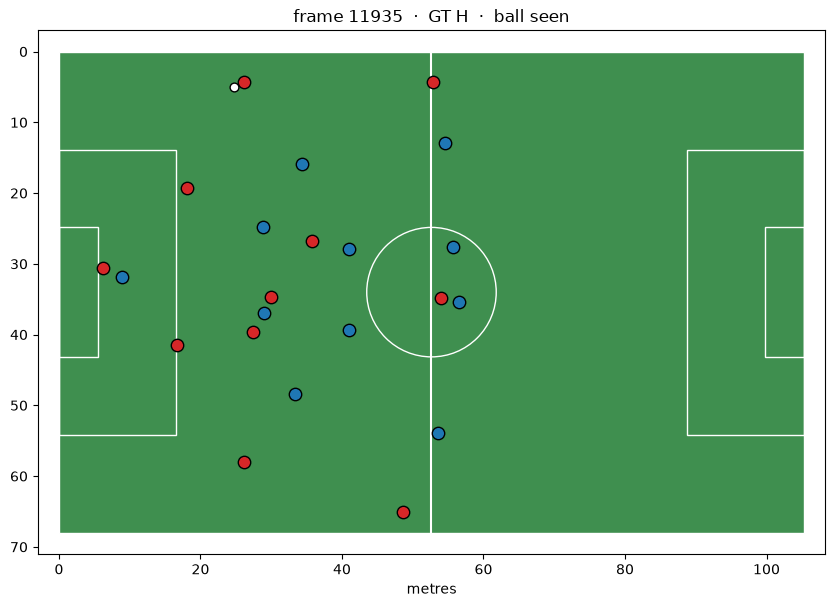

In [10]:
def plot_frame(i, ax=None):
    ax = draw_pitch(ax, *m.pitch)
    xy = m.players_xy[i]
    for team, colour in [(HOME, "#d62728"), (AWAY, "#1f77b4")]:
        sel = m.track_team == team
        ax.scatter(xy[sel, 0], xy[sel, 1], s=80, c=colour, edgecolor="k", zorder=3)
    if not np.isnan(m.ball_xy[i, 0]):
        ax.scatter(*m.ball_xy[i], s=40, c="white", edgecolor="k", zorder=4)
    ax.invert_yaxis()   # Metrica y = 0 is the top of the image: match the camera view
    ax.set_title(f"frame {i}  ·  GT {m.gt_public[i]}  ·  ball {'seen' if not np.isnan(m.ball_xy[i,0]) else 'MISSING'}")
    return ax

plot_frame(11185 + 25 * 30);  

## Where the ball goes missing
The single most important fact about the data. Per-minute share of frames with a ball position, over the graded play.

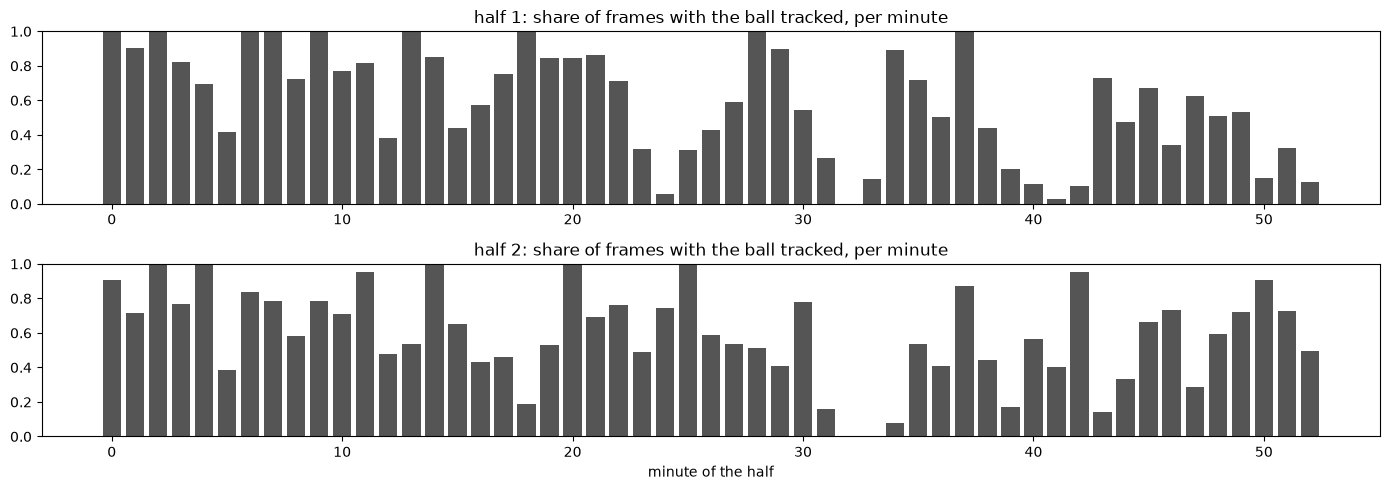

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharey=True)
for ax, h in zip(axes, (1, 2)):
    sel = frames[frames.half == h]
    per_min = sel.ball_seen.groupby((sel.index - sel.index[0]) // (25 * 60)).mean()
    ax.bar(per_min.index, per_min.values, color="#555")
    ax.set_title(f"half {h}: share of frames with the ball tracked, per minute")
    ax.set_ylim(0, 1)
axes[-1].set_xlabel("minute of the half")
plt.tight_layout()

150 gaps · median 10.72s · 90th pct 33.8s · longest 221s
share of missing time in gaps > 1 s: 100%


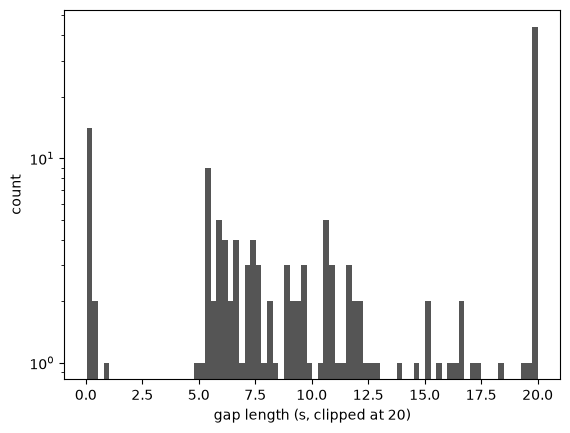

In [12]:
# Length of each continuous ball gap on graded frames
seen = frames.ball_seen.values & m.graded
edges = np.diff(np.r_[0, (~seen & m.graded).astype(int), 0])
gaps = (np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)) / 25
print(f"{len(gaps)} gaps · median {np.median(gaps):.2f}s · 90th pct {np.percentile(gaps, 90):.1f}s · longest {gaps.max():.0f}s")
print(f"share of missing time in gaps > 1 s: {gaps[gaps > 1].sum() / gaps.sum():.0%}")
plt.hist(np.clip(gaps, 0, 20), bins=80, color="#555"); plt.yscale("log")
plt.xlabel("gap length (s, clipped at 20)"); plt.ylabel("count");

## The public 5 minutes next ball location x and y
Understanding what H / A / D look like in the data

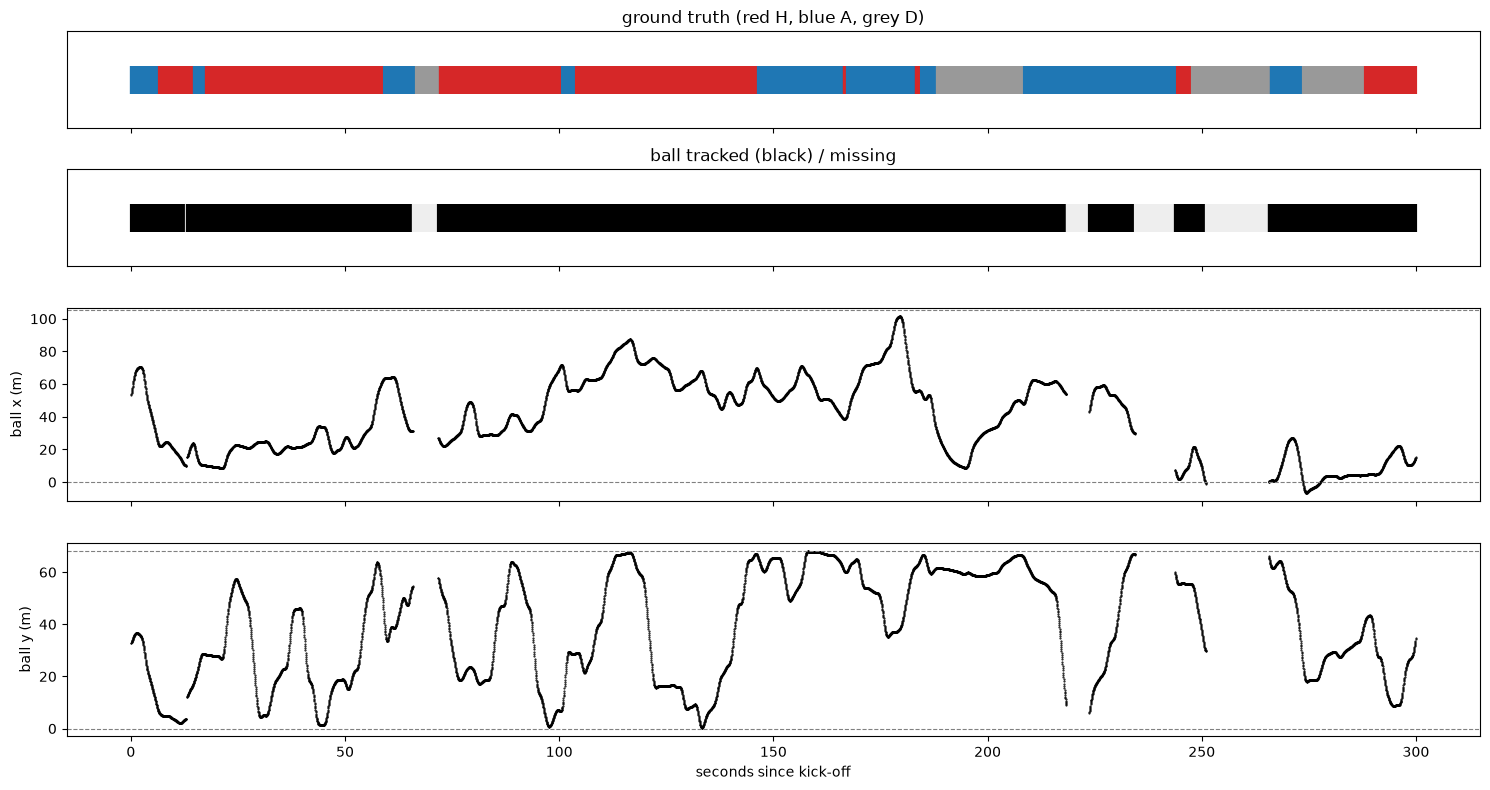

In [13]:
win = slice(11185, 18685)
t = (np.arange(win.start, win.stop) - win.start) / 25
colour = {"H": "#d62728", "A": "#1f77b4", "D": "#999999"}

fig, axes = plt.subplots(4, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1, 2, 2]})
axes[0].scatter(t, np.zeros_like(t), c=[colour[l] for l in m.gt_public[win]], marker="|", s=400)
axes[0].set_title("ground truth (red H, blue A, grey D)"); axes[0].set_yticks([])
axes[1].scatter(t, np.zeros_like(t), c=np.where(frames.ball_seen[win], "k", "#eee"), marker="|", s=400)
axes[1].set_title("ball tracked (black) / missing"); axes[1].set_yticks([])
axes[2].plot(t, m.ball_xy[win, 0], ".", ms=1, c="k")
axes[2].set_ylabel("ball x (m)")
for x_line in (0, m.pitch[0]): axes[2].axhline(x_line, ls="--", lw=.8, c="grey")   # goal lines
axes[3].plot(t, m.ball_xy[win, 1], ".", ms=1, c="k")
for y_line in (0, m.pitch[1]): axes[3].axhline(y_line, ls="--", lw=.8, c="grey")   # touchlines
axes[3].set_ylabel("ball y (m)"); axes[3].set_xlabel("seconds since kick-off")
plt.tight_layout()

## Smart Tagging

In [14]:
print(m.tags.code.value_counts().to_string())
m.tags.head(40)

code
PLAYERS IN THE BOX              97
BALL IN FINAL THIRD             93
BALL IN THE BOX                 72
DEFENDING IN MIDDLE THIRD       66
PROGRESSION                     66
SET PIECES                      59
CREATING CHANCES                30
DEFENDING IN DEFENSIVE THIRD    30
LONG BALL                       29
DEFENSIVE TRANSITION            24
ATTACKING TRANSITION            24
DEFENDING IN ATTACKING THIRD    22
BUILD UP                        22
GOALS                            4


,code,start_frame,end_frame,team,type,half,max players in the box,side,direction of ball entry,team_side
0,BALL IN FINAL THIRD,11069,12840,Atletic Club,NaN,1st Half,4,Central,NaN,A
1,LONG BALL,11085,11369,Atletic Club,NaN,1st Half,NaN,NaN,NaN,A
2,SET PIECES,11097,11222,N/A,Kick Off (Start),1st Half,NaN,NaN,NaN,NaN
3,DEFENDING IN MIDDLE THIRD,11204,12021,Barcelona,NaN,1st Half,NaN,NaN,NaN,H
4,PROGRESSION,11204,12021,Atletic Club,NaN,1st Half,NaN,NaN,NaN,A
5,PLAYERS IN THE BOX,11210,11887,Atletic Club,NaN,1st Half,4,NaN,NaN,A
6,BALL IN THE BOX,11319,11875,Atletic Club,NaN,1st Half,4,NaN,Horizontal,A
7,DEFENDING IN MIDDLE THIRD,12150,12662,Atletic Club,NaN,1st Half,NaN,NaN,NaN,A
8,PROGRESSION,12150,12662,Barcelona,NaN,1st Half,NaN,NaN,NaN,H
9,DEFENSIVE TRANSITION,12574,12851,Barcelona,NaN,1st Half,NaN,NaN,NaN,H


## Smart Tagging on a timeline

Each row is one tag code. Bars are coloured by the tagged team (red Barcelona, blue Athletic, grey N/A).
For the defending codes the tagged team is the *defending* side; each one mirrors an attacking tag with the same interval and the other team.
Set pieces are fixed 35 s windows, so only their start (the restart) means anything.

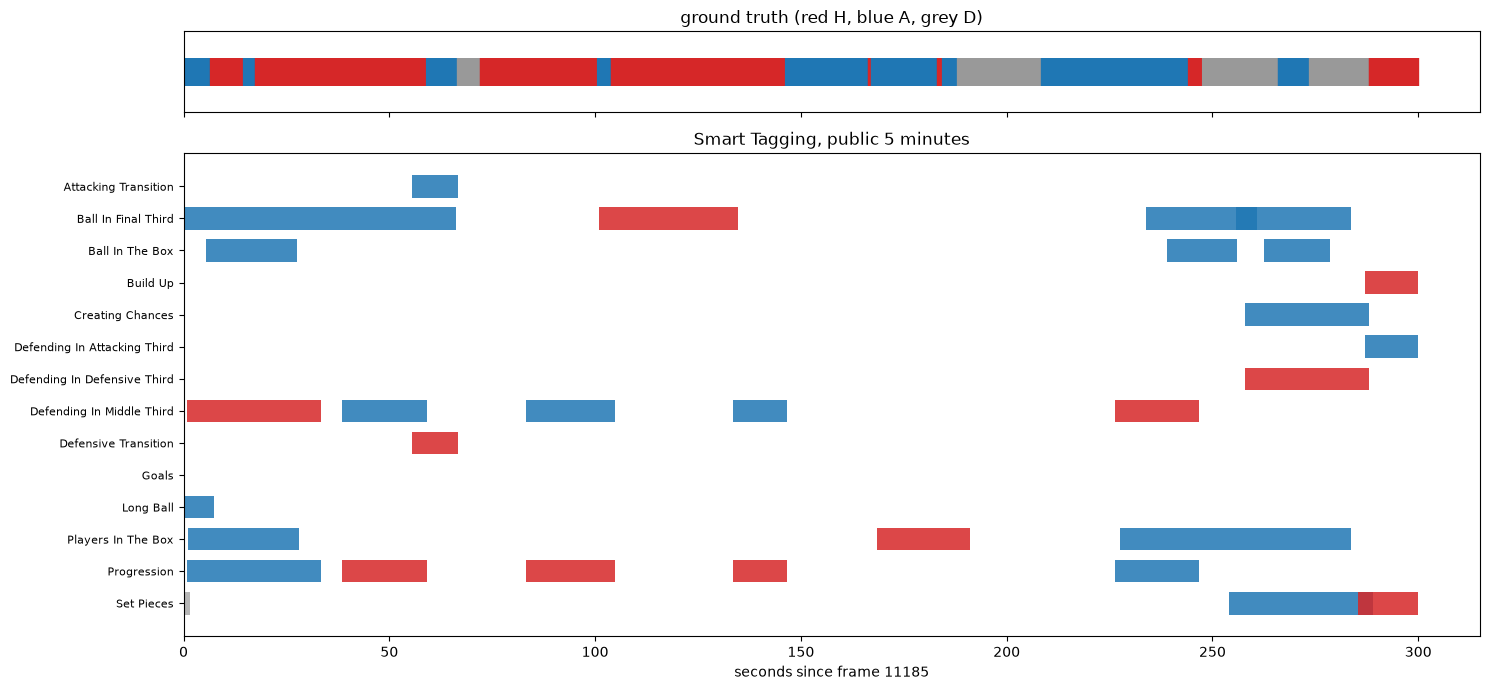

In [15]:
def plot_tags(start, stop, ax_tags, ax_gt=None):
    tags = m.tags[(m.tags.end_frame > start) & (m.tags.start_frame < stop)]
    codes = sorted(m.tags.code.unique())
    team_colour = {"H": "#d62728", "A": "#1f77b4"}
    for _, tag in tags.iterrows():
        row = codes.index(tag.code)
        a, b = max(tag.start_frame, start), min(tag.end_frame, stop)
        ax_tags.barh(row, (b - a) / 25, left=(a - start) / 25, height=0.7,
                     color=team_colour.get(tag.team_side, "#aaaaaa"), alpha=0.85)
    ax_tags.set_yticks(range(len(codes))); ax_tags.set_yticklabels([c.title() for c in codes], fontsize=8)
    ax_tags.invert_yaxis(); ax_tags.set_xlabel("seconds since frame {}".format(start))
    if ax_gt is not None:
        t = (np.arange(start, stop) - start) / 25
        labels = m.gt_public[start:stop]
        ax_gt.scatter(t, np.zeros_like(t), c=[colour.get(l, "white") for l in labels], marker="|", s=400)
        ax_gt.set_yticks([]); ax_gt.set_title("ground truth (red H, blue A, grey D)")

fig, (ax_gt, ax_tags) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios": [1, 6]})
plot_tags(11185, 18685, ax_tags, ax_gt)
ax_tags.set_title("Smart Tagging, public 5 minutes")
plt.tight_layout()

## Smart Tagging over the whole match: how many tags, and for which team

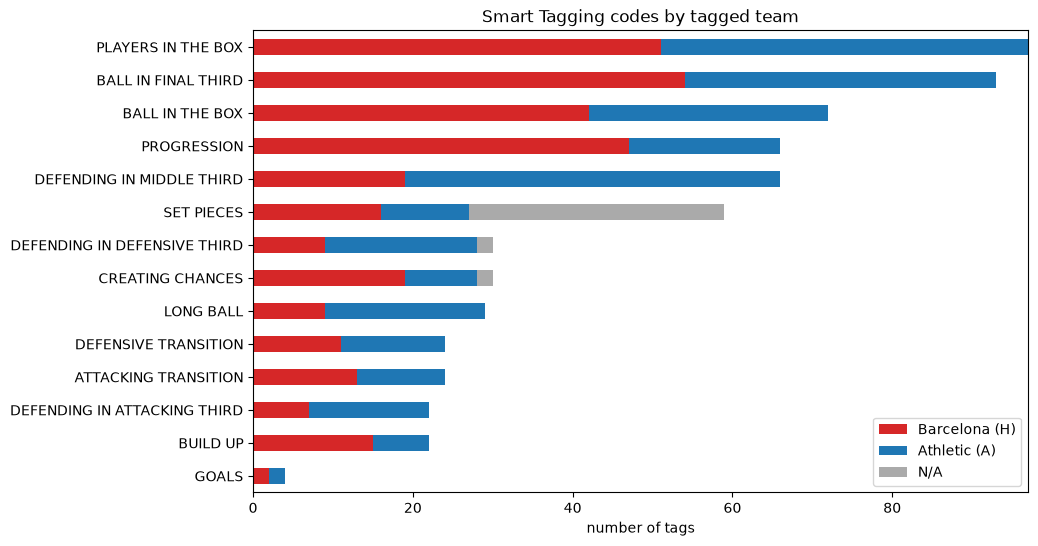

In [16]:
counts = (m.tags.assign(team=m.tags.team_side.fillna("N/A"))
          .groupby(["code", "team"]).size().unstack(fill_value=0)
          .reindex(columns=["H", "A", "N/A"], fill_value=0))
counts = counts.loc[counts.sum(axis=1).sort_values().index]
ax = counts.plot.barh(stacked=True, figsize=(10, 6), color=["#d62728", "#1f77b4", "#aaaaaa"])
ax.set_xlabel("number of tags"); ax.set_ylabel(""); ax.set_title("Smart Tagging codes by tagged team")
ax.legend(["Barcelona (H)", "Athletic (A)", "N/A"]);

### Smart Tagging on a timeline
One lane per tag code, coloured by the team the tag names (red Barcelona, blue Athletic, grey `N/A`). Defending tags name the *defending* team, so their colour is the team **without** the ball; they are exact mirrors of the attacking tags (same intervals). Set pieces are fixed 35 s windows: only their start (the restart) means anything.

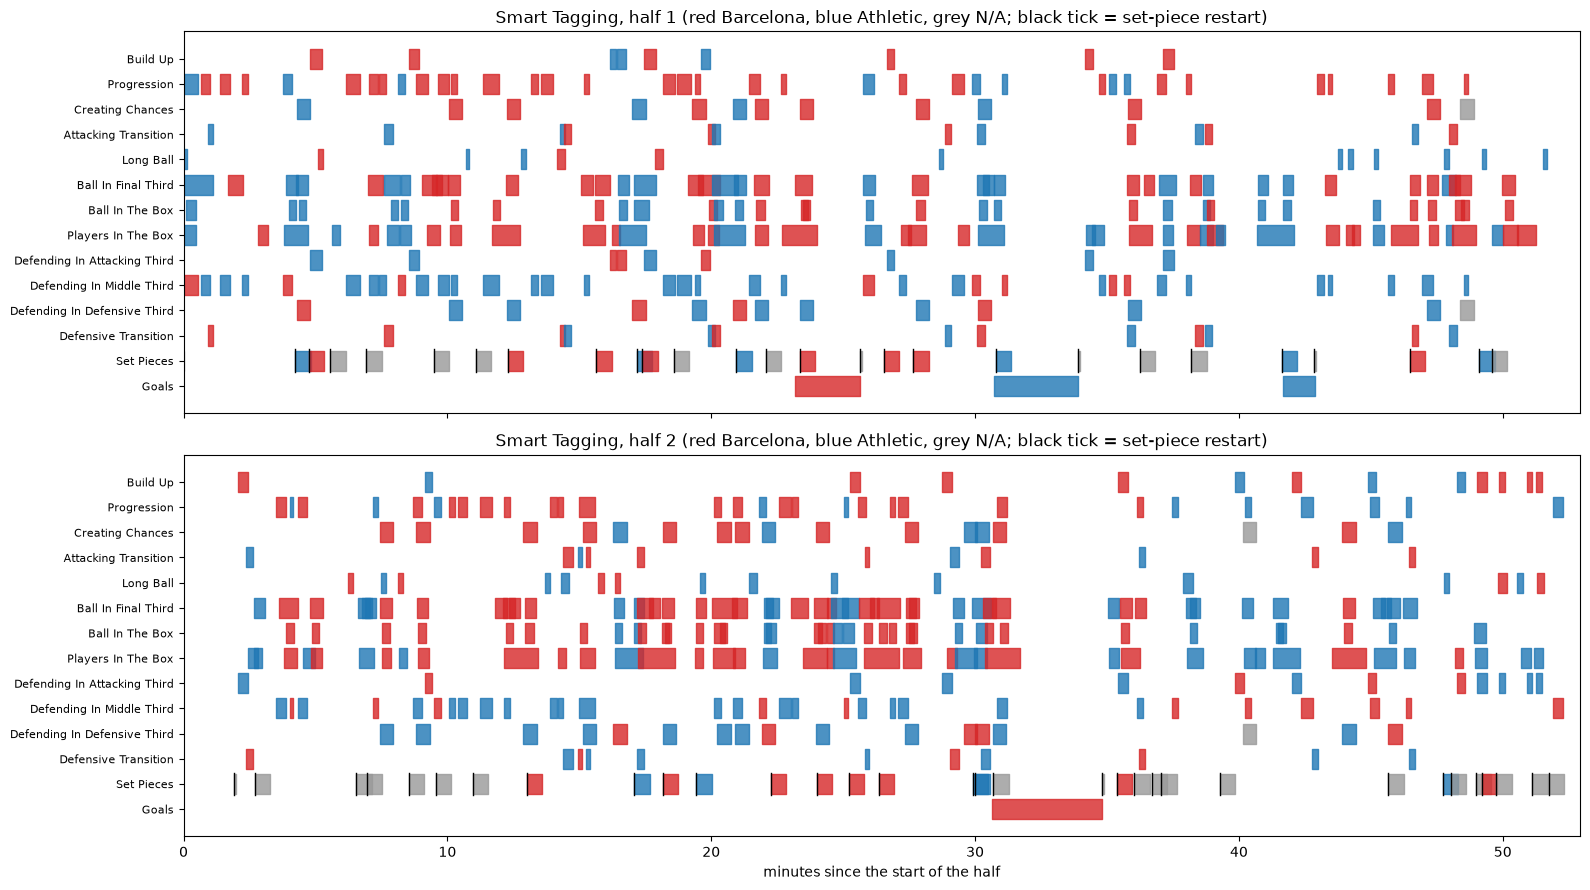

In [17]:
TEAM_COLOUR = {"H": "#d62728", "A": "#1f77b4"}
ORDER = ["BUILD UP", "PROGRESSION", "CREATING CHANCES", "ATTACKING TRANSITION", "LONG BALL",
         "BALL IN FINAL THIRD", "BALL IN THE BOX", "PLAYERS IN THE BOX",
         "DEFENDING IN ATTACKING THIRD", "DEFENDING IN MIDDLE THIRD", "DEFENDING IN DEFENSIVE THIRD",
         "DEFENSIVE TRANSITION", "SET PIECES", "GOALS"]

def plot_tags(ax, start, stop, minutes=True):
    sel = m.tags[(m.tags.end_frame > start) & (m.tags.start_frame < stop)]
    scale = 25 * 60 if minutes else 25
    for lane, code in enumerate(ORDER):
        rows = sel[sel.code == code]
        for r in rows.itertuples():
            colour = TEAM_COLOUR.get(r.team_side, "#999999")
            a, b = max(r.start_frame, start), min(r.end_frame, stop)
            ax.broken_barh([((a - start) / scale, (b - a) / scale)], (lane - 0.4, 0.8), color=colour, alpha=.8)
            if code == "SET PIECES":   # mark the restart moment
                ax.plot([(r.start_frame - start) / scale] * 2, [lane - .45, lane + .45], c="k", lw=1)
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels([c.title() for c in ORDER], fontsize=8)
    ax.invert_yaxis(); ax.set_xlim(0, (stop - start) / scale)

# whole match, one row per half
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for ax, (h, first, last) in zip(axes, [(1, 11185, 90651), (2, 110808, 190197)]):
    plot_tags(ax, first, last + 1)
    ax.set_title(f"Smart Tagging, half {h} (red Barcelona, blue Athletic, grey N/A; black tick = set-piece restart)")
axes[-1].set_xlabel("minutes since the start of the half")
plt.tight_layout()

### Zoom: the public 5 minutes, tags under the ground truth
For **understanding** only: how tag phases line up with real possessions (they are phases, not possessions, so expect them to be longer and to overlap turnovers).

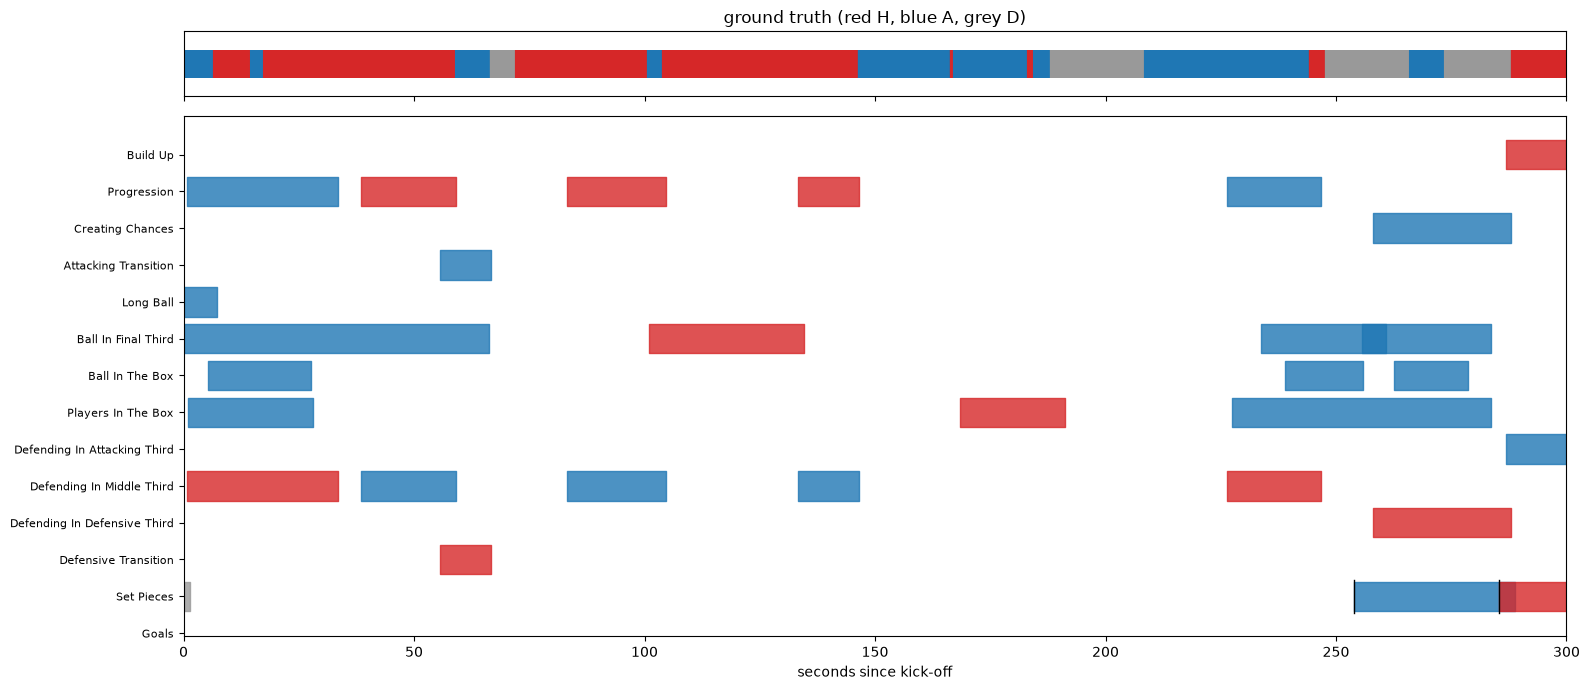

In [18]:
start, stop = 11185, 18685
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True, gridspec_kw={"height_ratios": [1, 8]})
t = np.arange(stop - start) / 25
axes[0].scatter(t, np.zeros_like(t), c=[colour[l] for l in m.gt_public[start:stop]], marker="|", s=400)
axes[0].set_yticks([]); axes[0].set_title("ground truth (red H, blue A, grey D)")
plot_tags(axes[1], start, stop, minutes=False)
axes[1].set_xlabel("seconds since kick-off")
plt.tight_layout()

## Out-of-play and ball-missing audit

This descriptive audit checks whether ball coordinates disappear after out-of-play/restart context. It informs the D/set-piece study; it never creates a prediction label.

In [19]:
# Purpose: quantify missing-ball behaviour around out-of-play and Smart Tagging restarts.
audit = atd_frame[['frame', 'ball_x', 'ball_y']].copy() if 'atd_frame' in globals() else m.atd[['frame', 'ball_x', 'ball_y']].copy()
audit['ball_missing'] = audit['ball_x'].isna() | audit['ball_y'].isna()
events = load_smart_tagging() if 'load_smart_tagging' in globals() else []
rows = []
for event in events:
    event_type = (event.get('tags', {}).get('Type') or '').strip()
    if not event_type:
        continue
    left, right = int(event['start_frame']), int(event['end_frame'])
    local = audit.loc[audit.frame.between(left, right)]
    rows.append({'restart_type': event_type, 'start_frame': left, 'end_frame': right, 'frames': len(local), 'missing_ball_frames': int(local.ball_missing.sum()), 'missing_ball_share': float(local.ball_missing.mean()) if len(local) else np.nan})
out_of_play_summary = pd.DataFrame(rows)
display(out_of_play_summary.groupby('restart_type', as_index=False).agg(events=('restart_type','size'), tagged_frames=('frames','sum'), missing_ball_frames=('missing_ball_frames','sum'), mean_missing_ball_share=('missing_ball_share','mean')) if not out_of_play_summary.empty else out_of_play_summary)
print('Interpretation: Smart Tagging tells us where to inspect; the measured missing-ball share tells us how much D protection is physically justified for each restart type.')

,restart_type,events,tagged_frames,missing_ball_frames,mean_missing_ball_share
0,Corner Kick,12,10512,4292,0.408295
1,Free Kick,5,4380,1778,0.405936
2,Goal Kick,10,8760,2337,0.266781
3,Kick Off (After Goal),4,504,366,0.726190
4,Kick Off (Start),2,252,90,0.357143
5,Throw-in,26,22776,5784,0.253952


Interpretation: Smart Tagging tells us where to inspect; the measured missing-ball share tells us how much D protection is physically justified for each restart type.
